# Airbnb Listing Price Analysis
## Exploratory Data Analysis (EDA) and Tableau Dashboard

**Project type:** Data Analysis  
**Dataset:** NYC Airbnb Open Data (2019) — expected file: `AB_NYC_2019.csv` or `airbnb_cleaned.csv`

### Objective
Explore Airbnb listing prices and listing characteristics, identify data-quality issues, compare prices by borough and room type, and generate evidence-based insights to support an interactive Tableau dashboard.

> This notebook focuses on descriptive analysis and visualization. It does not treat machine-learning predictions as the core deliverable. The dataset has no booking-date/month column, so it cannot support a true monthly price trend without an additional time-based dataset.

## 1. Import libraries and load the dataset

Run this notebook from top to bottom. If the CSV is not in the notebook's working folder, you will be prompted to upload it (Google Colab) or you can set `DATA_PATH` below.

In [1]:
import os
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

# Change this if your file is stored elsewhere.
DATA_PATH = "AB_NYC_2019.csv"

if not os.path.exists(DATA_PATH):
    if os.path.exists("airbnb_cleaned.csv"):
        DATA_PATH = "airbnb_cleaned.csv"
    else:
        try:
            from google.colab import files
            uploaded = files.upload()
            csv_files = [name for name in uploaded if name.lower().endswith(".csv")]
            if not csv_files:
                raise FileNotFoundError("Please upload an Airbnb CSV file.")
            # Prefer the original dataset if it was uploaded.
            DATA_PATH = next(
                (name for name in csv_files if name.lower() == "ab_nyc_2019.csv"),
                csv_files[0]
            )
        except ImportError:
            raise FileNotFoundError(
                "CSV not found. Put AB_NYC_2019.csv or airbnb_cleaned.csv "
                "in the notebook folder, or update DATA_PATH."
            )

df_raw = pd.read_csv(DATA_PATH)
print(f"Loaded file: {DATA_PATH}")
print(f"Raw dataset shape: {df_raw.shape[0]:,} rows × {df_raw.shape[1]} columns")
display(df_raw.head())

Saving airbnb_cleaned.csv to airbnb_cleaned.csv
Loaded file: airbnb_cleaned.csv
Raw dataset shape: 48,895 rows × 16 columns


,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
0,2539,Clean & quiet apt home by the park,2787,John,Brooklyn,Kensington,40.64749,-73.97237,Private room,149,1,9,2018-10-19,0.21,6,365
1,2595,Skylit Midtown Castle,2845,Jennifer,Manhattan,Midtown,40.75362,-73.98377,Entire home/apt,225,1,45,2019-05-21,0.38,2,355
2,3647,THE VILLAGE OF HARLEM....NEW YORK !,4632,Elisabeth,Manhattan,Harlem,40.80902,-73.94190,Private room,150,3,0,NaN,NaN,1,365
3,3831,Cozy Entire Floor of Brownstone,4869,LisaRoxanne,Brooklyn,Clinton Hill,40.68514,-73.95976,Entire home/apt,89,1,270,2019-07-05,4.64,1,194
4,5022,Entire Apt: Spacious Studio/Loft by central park,7192,Laura,Manhattan,East Harlem,40.79851,-73.94399,Entire home/apt,80,10,9,2018-11-19,0.10,1,0


## 2. Inspect the dataset

In [2]:
print("Column names:")
print(df_raw.columns.tolist())

print("\\nData types and non-null counts:")
df_raw.info()

print("\\nExact duplicate rows:", df_raw.duplicated().sum())

print("\\nMissing values by column:")
missing = pd.DataFrame({
    "missing_count": df_raw.isna().sum(),
    "missing_percent": (df_raw.isna().mean() * 100).round(2)
}).sort_values("missing_count", ascending=False)
display(missing)

print("\\nNumeric descriptive statistics:")
display(df_raw.describe().T)

Column names:
['id', 'name', 'host_id', 'host_name', 'neighbourhood_group', 'neighbourhood', 'latitude', 'longitude', 'room_type', 'price', 'minimum_nights', 'number_of_reviews', 'last_review', 'reviews_per_month', 'calculated_host_listings_count', 'availability_365']
\nData types and non-null counts:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48895 entries, 0 to 48894
Data columns (total 16 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   id                              48895 non-null  int64  
 1   name                            48879 non-null  object 
 2   host_id                         48895 non-null  int64  
 3   host_name                       48874 non-null  object 
 4   neighbourhood_group             48895 non-null  object 
 5   neighbourhood                   48895 non-null  object 
 6   latitude                        48895 non-null  float64
 7   longitude                       48

,missing_count,missing_percent
last_review,10052,20.56
reviews_per_month,10052,20.56
host_name,21,0.04
name,16,0.03
neighbourhood_group,0,0.00
neighbourhood,0,0.00
id,0,0.00
host_id,0,0.00
longitude,0,0.00
latitude,0,0.00


\nNumeric descriptive statistics:


,count,mean,std,min,25%,50%,75%,max
id,48895.0,1.901714e+07,1.098311e+07,2539.00000,9.471945e+06,1.967728e+07,2.915218e+07,3.648724e+07
host_id,48895.0,6.762001e+07,7.861097e+07,2438.00000,7.822033e+06,3.079382e+07,1.074344e+08,2.743213e+08
latitude,48895.0,4.072895e+01,5.453008e-02,40.49979,4.069010e+01,4.072307e+01,4.076311e+01,4.091306e+01
longitude,48895.0,-7.395217e+01,4.615674e-02,-74.24442,-7.398307e+01,-7.395568e+01,-7.393627e+01,-7.371299e+01
price,48895.0,1.527207e+02,2.401542e+02,0.00000,6.900000e+01,1.060000e+02,1.750000e+02,1.000000e+04
minimum_nights,48895.0,7.029962e+00,2.051055e+01,1.00000,1.000000e+00,3.000000e+00,5.000000e+00,1.250000e+03
number_of_reviews,48895.0,2.327447e+01,4.455058e+01,0.00000,1.000000e+00,5.000000e+00,2.400000e+01,6.290000e+02
reviews_per_month,38843.0,1.373221e+00,1.680442e+00,0.01000,1.900000e-01,7.200000e-01,2.020000e+00,5.850000e+01
calculated_host_listings_count,48895.0,7.143982e+00,3.295252e+01,1.00000,1.000000e+00,1.000000e+00,2.000000e+00,3.270000e+02
availability_365,48895.0,1.127813e+02,1.316223e+02,0.00000,0.000000e+00,4.500000e+01,2.270000e+02,3.650000e+02


## 3. Clean and prepare the data

Cleaning decisions are kept explicit:
- Remove exact duplicate rows.
- Standardize column names by trimming whitespace.
- Convert relevant numeric columns to numeric values where available.
- Keep missing review fields visible; do not automatically drop listings just because review information is missing.
- Create a separate analysis dataset excluding non-positive prices for price comparisons, while reporting how many rows were affected.
- Do not silently remove expensive listings. Inspect the distribution and report potential outliers separately.

In [3]:
df = df_raw.copy()
df.columns = df.columns.str.strip()

before_duplicates = len(df)
df = df.drop_duplicates().copy()
duplicates_removed = before_duplicates - len(df)

# Convert known numeric fields if they exist in this version of the dataset.
numeric_candidates = [
    "id", "host_id", "latitude", "longitude", "price", "minimum_nights",
    "number_of_reviews", "reviews_per_month",
    "calculated_host_listings_count", "availability_365"
]
for col in numeric_candidates:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors="coerce")

print(f"Exact duplicate rows removed: {duplicates_removed:,}")
print(f"Rows after duplicate removal: {len(df):,}")

if "price" not in df.columns:
    raise ValueError("The dataset must contain a 'price' column.")

nonpositive_price_count = int((df["price"].notna() & (df["price"] <= 0)).sum())
missing_price_count = int(df["price"].isna().sum())

df_price = df.loc[df["price"].notna() & (df["price"] > 0)].copy()

print(f"Missing price values: {missing_price_count:,}")
print(f"Zero or negative price records: {nonpositive_price_count:,}")
print(f"Rows retained for positive-price analysis: {len(df_price):,}")
display(df_price.head())

Exact duplicate rows removed: 0
Rows after duplicate removal: 48,895
Missing price values: 0
Zero or negative price records: 11
Rows retained for positive-price analysis: 48,884


,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
0,2539,Clean & quiet apt home by the park,2787,John,Brooklyn,Kensington,40.64749,-73.97237,Private room,149,1,9,2018-10-19,0.21,6,365
1,2595,Skylit Midtown Castle,2845,Jennifer,Manhattan,Midtown,40.75362,-73.98377,Entire home/apt,225,1,45,2019-05-21,0.38,2,355
2,3647,THE VILLAGE OF HARLEM....NEW YORK !,4632,Elisabeth,Manhattan,Harlem,40.80902,-73.94190,Private room,150,3,0,NaN,NaN,1,365
3,3831,Cozy Entire Floor of Brownstone,4869,LisaRoxanne,Brooklyn,Clinton Hill,40.68514,-73.95976,Entire home/apt,89,1,270,2019-07-05,4.64,1,194
4,5022,Entire Apt: Spacious Studio/Loft by central park,7192,Laura,Manhattan,East Harlem,40.79851,-73.94399,Entire home/apt,80,10,9,2018-11-19,0.10,1,0


## 4. Data-quality summary

In [4]:
quality_summary = pd.DataFrame({
    "Metric": [
        "Rows in original file",
        "Columns in original file",
        "Exact duplicates removed",
        "Missing price values",
        "Zero/negative price records",
        "Rows available for positive-price analysis"
    ],
    "Value": [
        len(df_raw),
        df_raw.shape[1],
        duplicates_removed,
        missing_price_count,
        nonpositive_price_count,
        len(df_price)
    ]
})
display(quality_summary)

# Check key categorical fields where present.
for col in ["neighbourhood_group", "neighbourhood", "room_type"]:
    if col in df_price.columns:
        print(f"Unique values in {col}: {df_price[col].nunique(dropna=True):,}")

,Metric,Value
0,Rows in original file,48895
1,Columns in original file,16
2,Exact duplicates removed,0
3,Missing price values,0
4,Zero/negative price records,11
5,Rows available for positive-price analysis,48884


Unique values in neighbourhood_group: 5
Unique values in neighbourhood: 221
Unique values in room_type: 3


## 5. Price distribution

Airbnb prices are often right-skewed. Compare the raw distribution with a view capped at the 99th percentile for readability. The capped plot is only for visualization; the underlying analysis data is not winsorized.

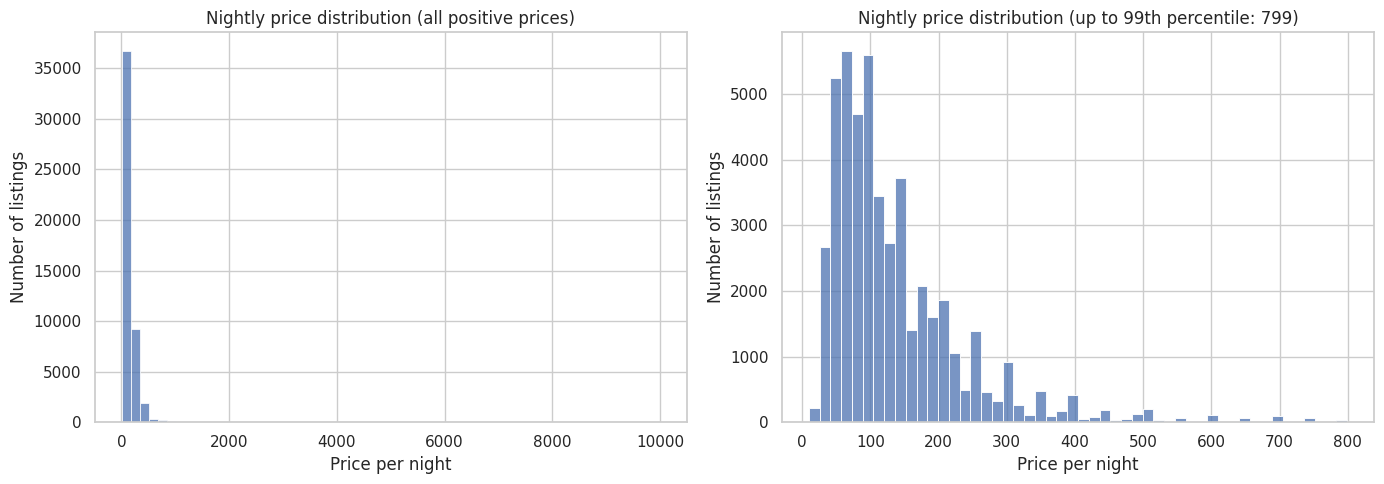

Price summary:


,price
count,48884.00
mean,152.76
std,240.17
min,10.00
25%,69.00
50%,106.00
75%,175.00
90%,269.00
95%,355.00
99%,799.00


Listings priced above the 99th percentile threshold (799.00): 474


In [5]:
price = df_price["price"].dropna()
p99 = price.quantile(0.99)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(price, bins=60, ax=axes[0])
axes[0].set_title("Nightly price distribution (all positive prices)")
axes[0].set_xlabel("Price per night")
axes[0].set_ylabel("Number of listings")

sns.histplot(price[price <= p99], bins=50, ax=axes[1])
axes[1].set_title(f"Nightly price distribution (up to 99th percentile: {p99:,.0f})")
axes[1].set_xlabel("Price per night")
axes[1].set_ylabel("Number of listings")
plt.tight_layout()
plt.show()

print("Price summary:")
display(price.describe(percentiles=[.25, .5, .75, .90, .95, .99]).to_frame("price").round(2))
print(f"Listings priced above the 99th percentile threshold ({p99:,.2f}): {(price > p99).sum():,}")

## 6. Compare price by borough / neighbourhood group

,listings,mean_price,median_price,min_price,max_price
neighbourhood_group,,,,,
Manhattan,21660,196.88,150.0,10,10000
Brooklyn,20095,124.44,90.0,10,10000
Queens,5666,99.52,75.0,10,10000
Staten Island,373,114.81,75.0,13,5000
Bronx,1090,87.58,65.0,10,2500


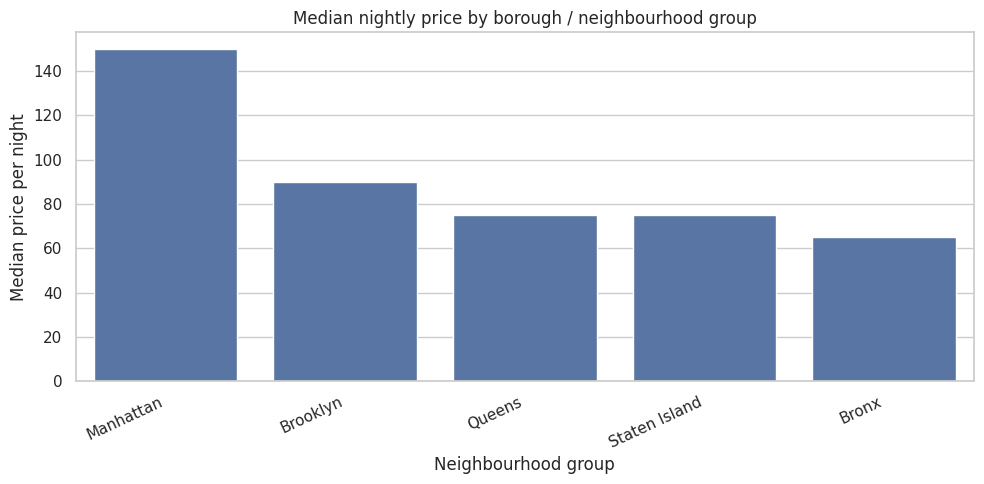

In [6]:
if "neighbourhood_group" in df_price.columns:
    borough_summary = (
        df_price.groupby("neighbourhood_group")["price"]
        .agg(listings="count", mean_price="mean", median_price="median",
             min_price="min", max_price="max")
        .sort_values("median_price", ascending=False)
        .round(2)
    )
    display(borough_summary)

    order = borough_summary.index.tolist()
    plt.figure(figsize=(10, 5))
    sns.barplot(data=df_price, x="neighbourhood_group", y="price",
                estimator=np.median, errorbar=None, order=order)
    plt.title("Median nightly price by borough / neighbourhood group")
    plt.xlabel("Neighbourhood group")
    plt.ylabel("Median price per night")
    plt.xticks(rotation=25, ha="right")
    plt.tight_layout()
    plt.show()
else:
    print("Column 'neighbourhood_group' not found; skip this analysis.")

## 7. Compare price by room type

,listings,mean_price,median_price,q25,q75
room_type,,,,,
Entire home/apt,25407,211.81,160.0,120.0,229.0
Private room,22319,89.81,70.0,50.0,95.0
Shared room,1158,70.25,45.0,33.0,75.0


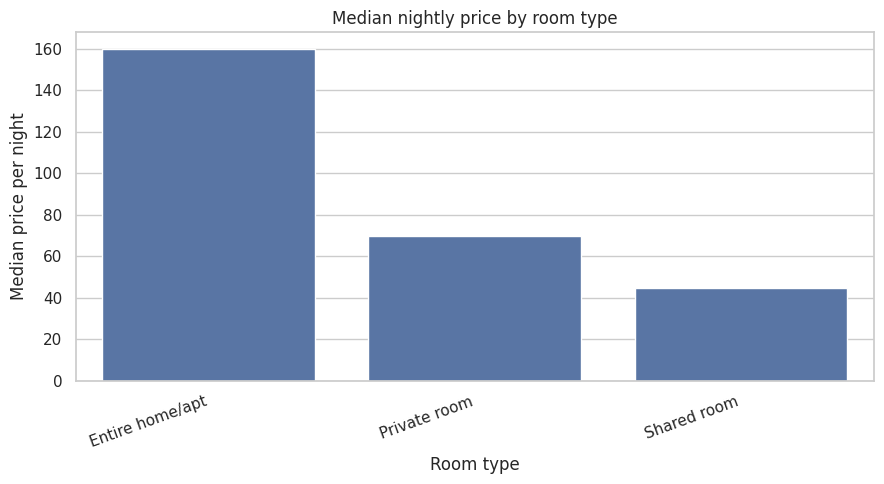

In [7]:
if "room_type" in df_price.columns:
    room_summary = (
        df_price.groupby("room_type")["price"]
        .agg(listings="count", mean_price="mean", median_price="median",
             q25=lambda s: s.quantile(.25), q75=lambda s: s.quantile(.75))
        .sort_values("median_price", ascending=False)
        .round(2)
    )
    display(room_summary)

    room_order = room_summary.index.tolist()
    plt.figure(figsize=(9, 5))
    sns.barplot(data=df_price, x="room_type", y="price",
                estimator=np.median, errorbar=None, order=room_order)
    plt.title("Median nightly price by room type")
    plt.xlabel("Room type")
    plt.ylabel("Median price per night")
    plt.xticks(rotation=20, ha="right")
    plt.tight_layout()
    plt.show()
else:
    print("Column 'room_type' not found; skip this analysis.")

## 8. Most expensive neighbourhoods (minimum listing count applied)

Showing neighbourhoods with at least 20 listings.


,listings,median_price,mean_price
neighbourhood,,,
Tribeca,177,295.0,490.64
NoHo,78,250.0,295.72
Flatiron District,80,225.0,341.92
Midtown,1545,210.0,282.72
West Village,768,200.0,267.68
Financial District,744,200.0,225.49
Chelsea,1113,199.0,249.74
SoHo,358,199.0,287.10
Greenwich Village,392,197.5,263.41


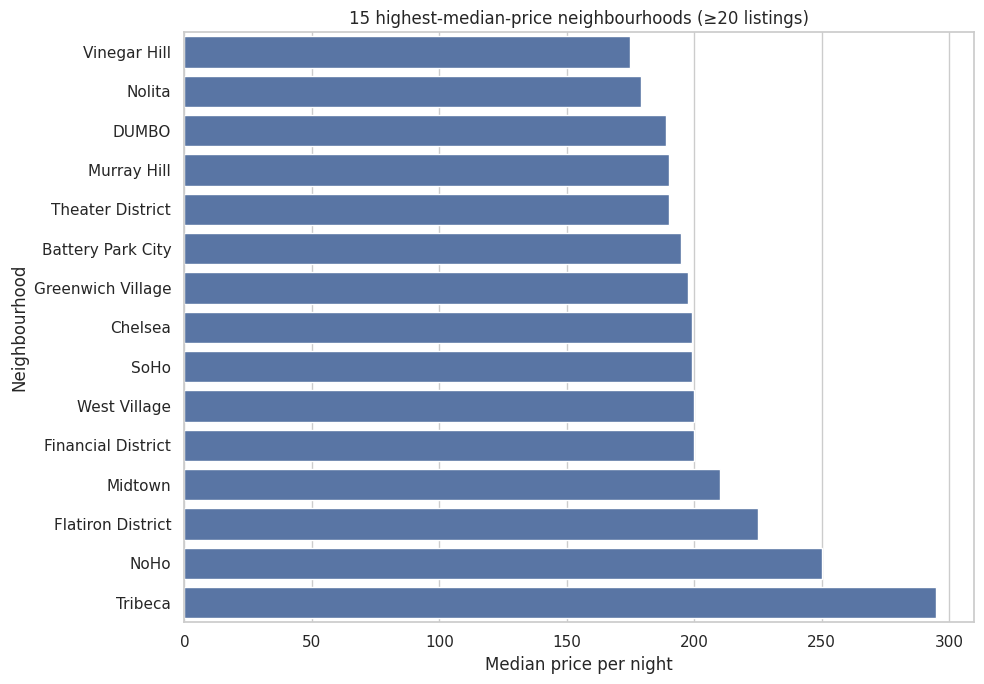

In [8]:
if "neighbourhood" in df_price.columns:
    neighbourhood_summary = (
        df_price.groupby("neighbourhood")["price"]
        .agg(listings="count", median_price="median", mean_price="mean")
    )
    # Avoid ranking neighbourhoods based on only a handful of listings.
    MIN_LISTINGS = 20
    neighbourhood_summary_filtered = neighbourhood_summary[
        neighbourhood_summary["listings"] >= MIN_LISTINGS
    ].sort_values("median_price", ascending=False)

    print(f"Showing neighbourhoods with at least {MIN_LISTINGS} listings.")
    display(neighbourhood_summary_filtered.head(15).round(2))

    top_neighbourhoods = neighbourhood_summary_filtered.head(15).sort_values("median_price")
    if not top_neighbourhoods.empty:
        plt.figure(figsize=(10, 7))
        sns.barplot(data=top_neighbourhoods.reset_index(),
                    x="median_price", y="neighbourhood")
        plt.title(f"15 highest-median-price neighbourhoods (≥{MIN_LISTINGS} listings)")
        plt.xlabel("Median price per night")
        plt.ylabel("Neighbourhood")
        plt.tight_layout()
        plt.show()
else:
    print("Column 'neighbourhood' not found; skip this analysis.")

## 9. Listing supply by area and room type

,neighbourhood_group,listing_count
0,Manhattan,21660
1,Brooklyn,20095
2,Queens,5666
3,Bronx,1090
4,Staten Island,373


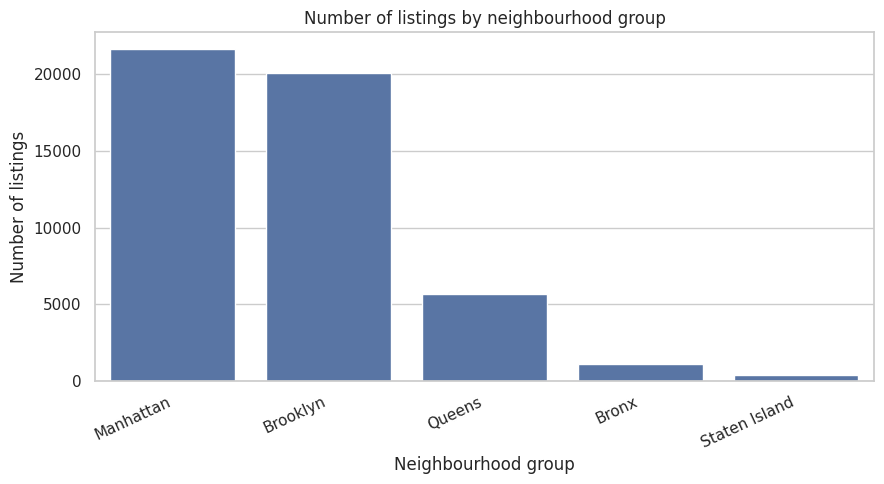

room_type,Entire home/apt,Private room,Shared room
neighbourhood_group,,,
Bronx,379,651,60
Brooklyn,9558,10126,411
Manhattan,13198,7982,480
Queens,2096,3372,198
Staten Island,176,188,9


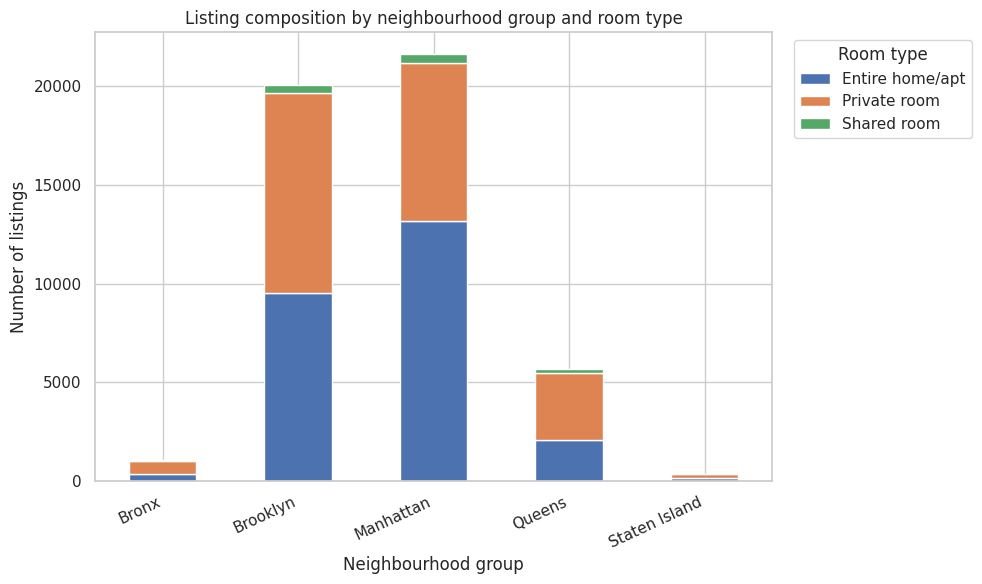

In [9]:
if "neighbourhood_group" in df_price.columns:
    listings_by_area = df_price["neighbourhood_group"].value_counts().rename_axis(
        "neighbourhood_group"
    ).reset_index(name="listing_count")
    display(listings_by_area)

    plt.figure(figsize=(9, 5))
    sns.barplot(data=listings_by_area, x="neighbourhood_group", y="listing_count")
    plt.title("Number of listings by neighbourhood group")
    plt.xlabel("Neighbourhood group")
    plt.ylabel("Number of listings")
    plt.xticks(rotation=25, ha="right")
    plt.tight_layout()
    plt.show()

if {"neighbourhood_group", "room_type"}.issubset(df_price.columns):
    mix = pd.crosstab(df_price["neighbourhood_group"], df_price["room_type"])
    display(mix)
    mix.plot(kind="bar", stacked=True, figsize=(10, 6))
    plt.title("Listing composition by neighbourhood group and room type")
    plt.xlabel("Neighbourhood group")
    plt.ylabel("Number of listings")
    plt.xticks(rotation=25, ha="right")
    plt.legend(title="Room type", bbox_to_anchor=(1.02, 1), loc="upper left")
    plt.tight_layout()
    plt.show()

## 10. Availability and minimum-night patterns

These fields describe listing settings, not actual bookings. Do not interpret availability as occupancy or demand without additional data.

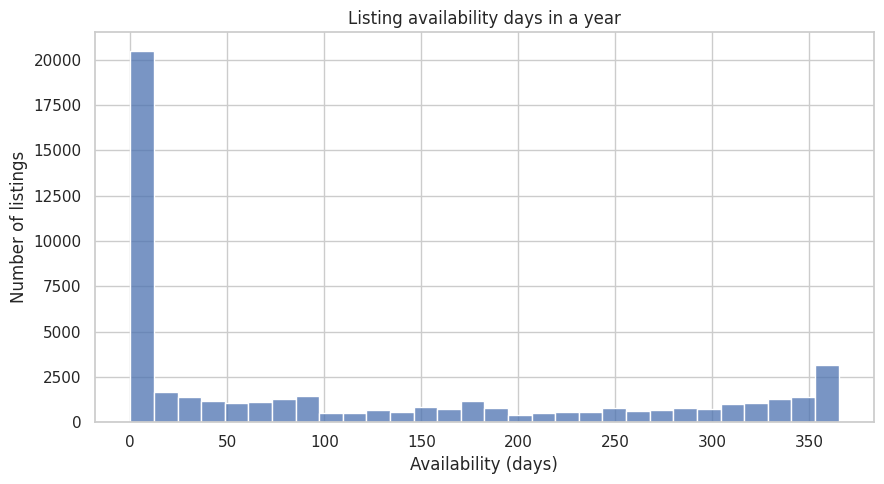

Minimum nights summary:


,minimum_nights
count,48884.00
mean,7.03
std,20.51
min,1.00
50%,3.00
75%,5.00
90%,28.00
95%,30.00
99%,45.00
max,1250.00


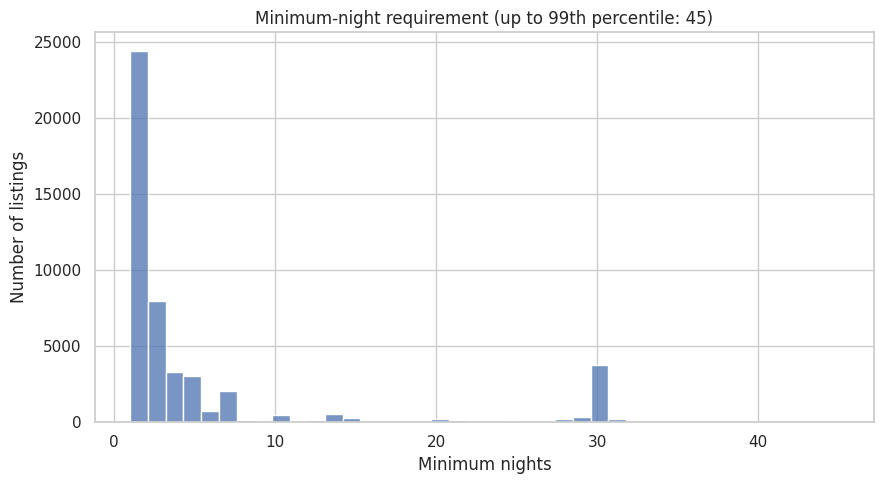

In [10]:
if "availability_365" in df_price.columns:
    plt.figure(figsize=(9, 5))
    sns.histplot(df_price["availability_365"].dropna(), bins=30)
    plt.title("Listing availability days in a year")
    plt.xlabel("Availability (days)")
    plt.ylabel("Number of listings")
    plt.tight_layout()
    plt.show()

if "minimum_nights" in df_price.columns:
    print("Minimum nights summary:")
    display(df_price["minimum_nights"].describe(percentiles=[.5, .75, .9, .95, .99]).to_frame().round(2))

    cap = df_price["minimum_nights"].quantile(.99)
    plt.figure(figsize=(9, 5))
    sns.histplot(df_price.loc[df_price["minimum_nights"] <= cap, "minimum_nights"], bins=40)
    plt.title(f"Minimum-night requirement (up to 99th percentile: {cap:.0f})")
    plt.xlabel("Minimum nights")
    plt.ylabel("Number of listings")
    plt.tight_layout()
    plt.show()

## 11. Relationships between price and listing characteristics

Use median prices for group comparisons because extreme prices can pull the mean upward. Correlation is shown only for numeric fields and should not be interpreted as causation.

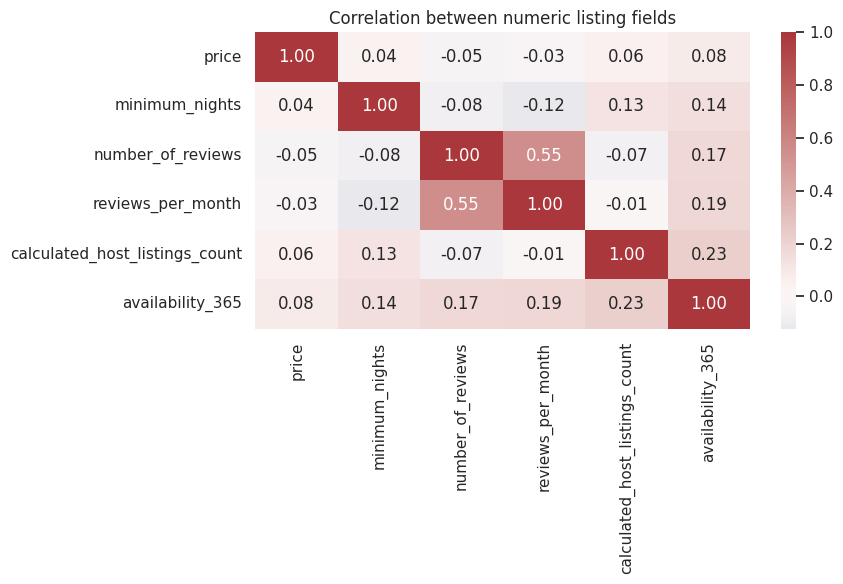

,price,minimum_nights,number_of_reviews,reviews_per_month,calculated_host_listings_count,availability_365
price,1.000,0.043,-0.048,-0.031,0.057,0.082
minimum_nights,0.043,1.000,-0.080,-0.122,0.128,0.144
number_of_reviews,-0.048,-0.080,1.000,0.550,-0.072,0.172
reviews_per_month,-0.031,-0.122,0.550,1.000,-0.009,0.186
calculated_host_listings_count,0.057,0.128,-0.072,-0.009,1.000,0.226
availability_365,0.082,0.144,0.172,0.186,0.226,1.000


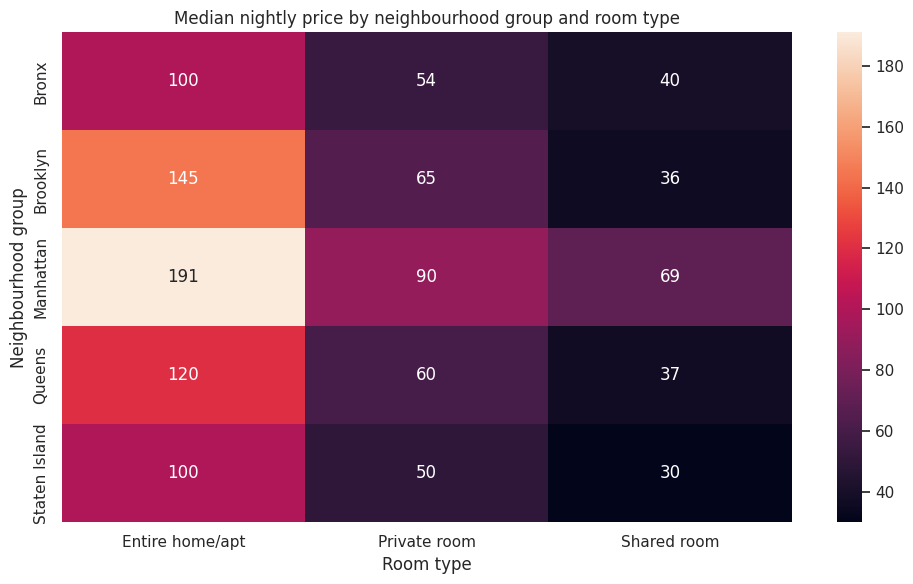

room_type,Entire home/apt,Private room,Shared room
neighbourhood_group,,,
Bronx,100.0,54.0,40.0
Brooklyn,145.0,65.0,36.0
Manhattan,191.0,90.0,69.0
Queens,120.0,60.0,37.0
Staten Island,100.0,50.0,30.0


In [11]:
numeric_for_corr = [
    c for c in [
        "price", "minimum_nights", "number_of_reviews", "reviews_per_month",
        "calculated_host_listings_count", "availability_365"
    ] if c in df_price.columns
]

if len(numeric_for_corr) >= 2:
    corr = df_price[numeric_for_corr].corr(numeric_only=True)
    plt.figure(figsize=(9, 6))
    sns.heatmap(corr, annot=True, fmt=".2f", cmap="vlag", center=0)
    plt.title("Correlation between numeric listing fields")
    plt.tight_layout()
    plt.show()
    display(corr.round(3))
else:
    print("Not enough numeric fields available for a correlation heatmap.")

if {"room_type", "neighbourhood_group"}.issubset(df_price.columns):
    pivot = df_price.pivot_table(
        index="neighbourhood_group", columns="room_type",
        values="price", aggfunc="median"
    )
    plt.figure(figsize=(10, 6))
    sns.heatmap(pivot, annot=True, fmt=".0f")
    plt.title("Median nightly price by neighbourhood group and room type")
    plt.xlabel("Room type")
    plt.ylabel("Neighbourhood group")
    plt.tight_layout()
    plt.show()
    display(pivot.round(2))

## 12. Generate concise findings from the data

These are calculated summaries, not pre-written conclusions. Use the results to write your final business insights and validate any statement you include in your report.

In [12]:
print("===== KEY DATA SUMMARY =====")
print(f"Listings in original file: {len(df_raw):,}")
print(f"Listings used in positive-price analysis: {len(df_price):,}")
print(f"Median nightly price: {df_price['price'].median():,.2f}")
print(f"Mean nightly price: {df_price['price'].mean():,.2f}")
print(f"99th percentile price: {df_price['price'].quantile(.99):,.2f}")

if "neighbourhood_group" in df_price.columns:
    medians = df_price.groupby("neighbourhood_group")["price"].median().sort_values(ascending=False)
    print(f"Highest median price by neighbourhood group: {medians.index[0]} ({medians.iloc[0]:,.2f})")
    print(f"Lowest median price by neighbourhood group: {medians.index[-1]} ({medians.iloc[-1]:,.2f})")

if "room_type" in df_price.columns:
    medians_room = df_price.groupby("room_type")["price"].median().sort_values(ascending=False)
    print(f"Highest median price by room type: {medians_room.index[0]} ({medians_room.iloc[0]:,.2f})")
    print(f"Lowest median price by room type: {medians_room.index[-1]} ({medians_room.iloc[-1]:,.2f})")

print("\\nWrite 4–6 evidence-based insights after reviewing the tables and charts.")

===== KEY DATA SUMMARY =====
Listings in original file: 48,895
Listings used in positive-price analysis: 48,884
Median nightly price: 106.00
Mean nightly price: 152.76
99th percentile price: 799.00
Highest median price by neighbourhood group: Manhattan (150.00)
Lowest median price by neighbourhood group: Bronx (65.00)
Highest median price by room type: Entire home/apt (160.00)
Lowest median price by room type: Shared room (45.00)
\nWrite 4–6 evidence-based insights after reviewing the tables and charts.


## 13. Export analysis-ready data for Tableau

Exports the cleaned listing-level dataset and a compact summary table. These exports are descriptive-analysis assets; they do not contain model predictions.

In [15]:
# Save cleaned listing data used in analysis.
df_price.to_csv("airbnb_eda_cleaned.csv", index=False)
# Download the CSV
from google.colab import files
files.download('airbnb_eda_cleaned.csv')

# Summary export for Tableau: median and mean price by area and room type.
summary_fields = [c for c in ["neighbourhood_group", "room_type"] if c in df_price.columns]
if summary_fields:
    tableau_summary = (
        df_price.groupby(summary_fields)["price"]
        .agg(listings="count", mean_price="mean", median_price="median")
        .reset_index()
    )
    tableau_summary.to_csv("airbnb_price_summary_tableau.csv", index=False)
    display(tableau_summary.head(20))

print("Saved: airbnb_eda_cleaned.csv")
if summary_fields:
    print("Saved: airbnb_price_summary_tableau.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

,neighbourhood_group,room_type,listings,mean_price,median_price
0,Bronx,Entire home/apt,379,127.506596,100.0
1,Bronx,Private room,651,66.890937,54.0
2,Bronx,Shared room,60,59.800000,40.0
3,Brooklyn,Entire home/apt,9558,178.346202,145.0
4,Brooklyn,Private room,10126,76.545428,65.0
5,Brooklyn,Shared room,411,50.773723,36.0
6,Manhattan,Entire home/apt,13198,249.257994,191.0
7,Manhattan,Private room,7982,116.776622,90.0
8,Manhattan,Shared room,480,88.977083,69.0
9,Queens,Entire home/apt,2096,147.050573,120.0


Saved: airbnb_eda_cleaned.csv
Saved: airbnb_price_summary_tableau.csv


## 14. Tableau dashboard recommendations
Dashboard views:
1. KPI cards: total listings, median nightly price, mean nightly price, and price 99th percentile.
2. Median price by neighbourhood group.
3. Median price by room type.
4. Neighbourhood price ranking with a minimum listing-count threshold.
5. Listing count by area and room-type composition.
6. Filters: neighbourhood group, neighbourhood, room type, price range, and minimum nights.

**Important data limitation:** the 2019 listing dataset has no booking-date or monthly time field. Do not label a chart “monthly price trend” unless you bring in a valid date-based dataset and explain what its dates represent.
